## Individual Code Review

There are many different ways to plot data sets in 3 dimensional graphs with a variety of use cases. If that data can be represented using points in space that change with time, such as positional arguments of point masses with a time dependency, then an animated 3D scatter plot is a very intuatuve way to visualize it. Some examples of use cases where this may be true are gas simulations, chemical reactions, population simulations, fluid dynamics, and for the example of this document, celestial mechanics.

Plotly provides a 3d scatter plot that can be modified to animate data using a variety of methods such as initializing graph objects, or for a simpler approach, using their express features.

### Plotly Express Basics

There are a couple ways of going about creating your desired plot, first I will use plotly express to get a simple, easy to use graph working. Then, I will go over graph objects to create more detailed or specialized animations

To get plotly express in your notebook, import it by using:
>import plotly.express as px

First, create your data set. 
For this example I am going to create two points that will be moving in opposite directions.

In [1]:
import numpy as np

points = np.zeros([2, 6]) # Creating two points with 6 arguments, 3 positions, 3 velocities

# Setting values of positions and velocities
points[0, 0:3] = ([-5, 6, 5])
points[0, 3:7] = ([1, -1, -1])
points[1, 0:3] = ([5, -6, -5])
points[1, 3:7] = ([-1, 1, 1])

Next, the initial data set needs to be developed over some time, and stored into a saved list for plotly to access when plotting. To do this I am just using the euler method to progress the points by the velocity. At every dt, the x, y, and z positions of the points are written to 'frames' using frames.append no the empty list 'frames' created before the loop. The frame number tells plotly what order to put the frames in and needs to be progressed over the loop.

In [2]:
time = 10
dt = 0.01
t = 0

frames = []
frame_number = 0
while t < time:
    for i in range(2):
        frames.append((points[i,0], points[i,1], points[i,2], frame_number))
        
    points[:,0:3] += points[:,3:7] * dt
    
    t += dt
    frame_number += 1

To plot the data, the list needs to be converted to a tabular data structure with columns that plotly can understand. I chose to do this by using pandas, converting the frames list to a data frame with columns x, y, z, and frame, which plotly will understand as the positional arguments, and the frame at which the positions should be active.

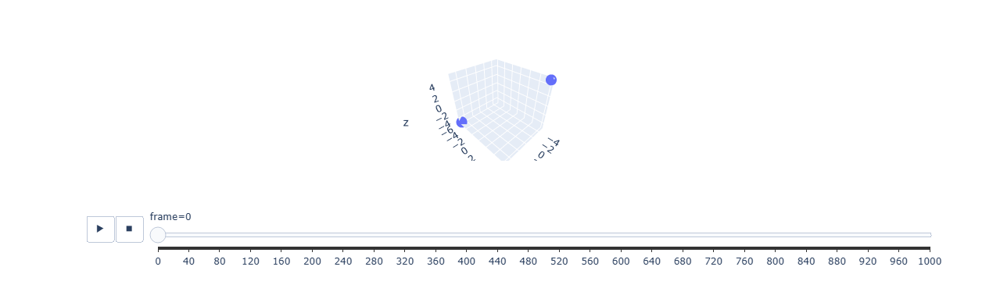

In [3]:
import pandas as pd
import plotly.express as px

data_frame = pd.DataFrame(frames, columns=['x','y','z','frame'])

fig = px.scatter_3d(
    data_frame,
    x='x',
    y='y',
    z='z',
    animation_frame='frame',
)

fig.show()

### Plotly Express 3D Scatter Plot Animation

While this does visualize the data, there are a couple issues with this plot. Firstly, the animation is computationaly expensive, despite only doing 1000 calculations. The animation is also incredibly slow, to the point where the only way to see whats happening is to use the timeline. The bounds of the plot move with the points, which makes it difficult to tell what is going on, and finally, the points are the same color, which makes it harder to understand.

Luckily, there are some simple steps we can take to improve it drastically. To make the code more efficient, frames dont need to be taken every dt step, instead, a frameskip can be used to only record a frame every 'x' simulation step. The duration and transition of the frames can be controlled through changing the layout. The frame duration and transition are taken as milliseconds by default. The bounds of the plot, along with the aspect ratio of each axis can be set using update layout. The color of the points can be controlled by giving each point a constant value and relating that value to a color so that at every frame, the points have different constant colors. 

To create a frame skip, a constant value can be used, and at each simulation step, the frame writing code is behind an if statement that sees if the frame number is divisible by the frame skip. Meaning that if the frame skip is 5, the list is only updated every 5 frames when the remainder of the two values is 0.

I also added a width and height element to the figure so that it is easier to use in notebooks.

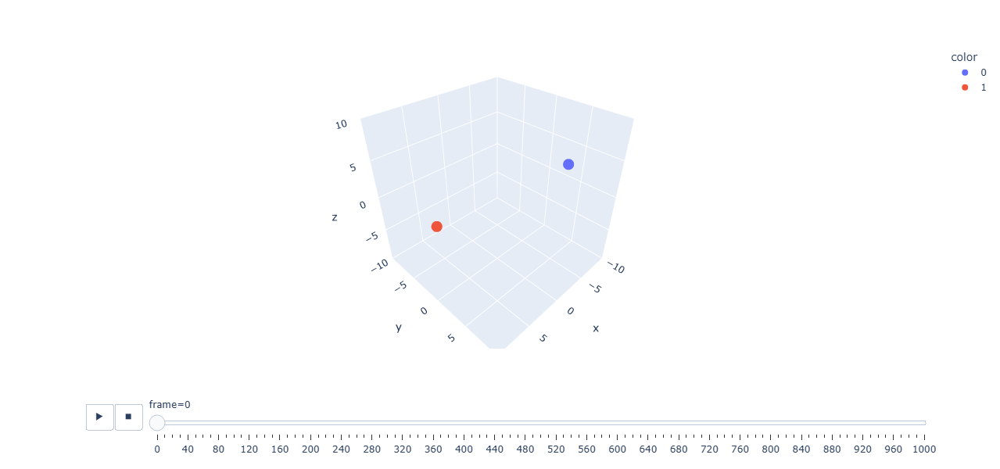

In [4]:
import numpy as np

points = np.zeros([2, 6])
points[0, 0:3] = ([-5, 6, 5])
points[0, 3:7] = ([1, -1, -1])
points[1, 0:3] = ([5, -6, -5])
points[1, 3:7] = ([-1, 1, 1])

time = 10
dt = 0.01
t = 0
R = 10

frames = []
frame_number = 0
frame_skip = 10
while t < time:
    if frame_number % frame_skip == 0: # Testing if the remainder of the frame number / frame skip is 0
        for i in range(2):
            # Adding a string conversion of i that gives a value corresponding to the point
            frames.append((points[i,0], points[i,1], points[i,2], str(i), frame_number)) 
        
    points[:,0:3] += points[:,3:7] * dt
    
    t += dt
    frame_number += 1

import pandas as pd
import plotly.express as px

data_frame = pd.DataFrame(frames, columns=['x','y','z','color','frame']) # Updating the data frame to have a color value

fig = px.scatter_3d(
    data_frame,
    x='x',
    y='y',
    z='z',
    color='color', # Setting the color to the string value
    animation_frame='frame',
    # Width and height argument for the figure
    width=600, 
    height=600,
)

#Setting the frame duration to 10 milliseconds, and the transition to 1 millisecond
fig.layout.updatemenus[0].buttons[0].args[1]['frame']['duration'] = 10
fig.layout.updatemenus[0].buttons[0].args[1]['transition']['duration'] = 1

#Updating the scene so that the axis are dependent on a variable constant with a cubic aspect ratio
fig.update_layout(
    scene=dict(
        xaxis=dict(range=[-R, R]),
        yaxis=dict(range=[-R, R]),
        zaxis=dict(range=[-R, R]),
        aspectmode='cube'
    )
)

fig.show()

Now the given data that changes over time is fairly readable and easy to edit depending on the number of objects, length of the simulation, or size of the volume.

### Example from Orbital Mechanics

A larger example of how this can be used is in celestial orbits. Since the masses of objects can be assumed to be point masses, and the motion of every object is incredibly important to the orbital mechanics, a 3D animated scatter plot is a very good way to visualize gravitational systems

The following code runs a binary star solar system that evolves over time due to the force of gravity between every object, given a random push that makes the system unstable. The code to plot the data works the exact same as the previous example, taking the positional objects every frame skip, except there are more objects.

In [5]:
# Function Initialization

def force_calculation(objects, N, G, soft_len, dt, frame_num):
    #Sets force equal to 0
    objects[:,7:10] = 0
    
    #Records current object position and frame
    if frame_num % frame_skip == 0:
        for i in range(N):
            frames.append((objects[i,1], objects[i,2], objects[i,3], str(i), frame_num/frame_skip))
    
    #Calculating the force between every object
    for i in range(N):
        for j in range(i+1,N):
            if i != j:
                r = objects[j,1:4] - objects[i,1:4]
                r_dot = np.dot(r,r)
                
                F = -G * objects[i,0] * objects[j,0] * (r / (r_dot + soft_len**2)**1.5)
                
                objects[i,7:10] -= F
                objects[j,7:10] += F
                
    #Updating momentum
    objects[:,4:7] += objects[:,7:10] * dt
    
    #Updating Position
    for i in range(N): #Put in for loop so that mass is a scalar instead of an array of different shape from momentum. [find better solution?]
        objects[i,1:4] += (objects[i,4:7] / objects[i,0]) * dt
    
    return(frames, objects[:,4:7])

def anim_plot(df,R,title):
    fig = px.scatter_3d(
        df,
        x='x',
        y='y',
        z='z',
        color='object',
        animation_frame='frame',
        title=title,
        width=600, 
        height=600,
    )

    fig.layout.updatemenus[0].buttons[0].args[1]['frame']['duration'] = 10
    fig.layout.updatemenus[0].buttons[0].args[1]['transition']['duration'] = 1

    fig.update_layout(
        scene=dict(
            xaxis=dict(range=[-2*R, 2*R]),
            yaxis=dict(range=[-2*R, 2*R]),
            zaxis=dict(range=[-2*R, 2*R]),
            aspectmode='cube'
        )
    )
    
    return(fig)

def initial_planet_p(objects, N, r_cm, orbital_plane):
    for n in range(2,N):
        r = r_cm - np.array([objects[n,1], objects[n,2], objects[n,3]])
        r_mag = np.linalg.norm(r)
        r_hat  = r/r_mag

        theta_hat = np.cross(orbital_plane, r_hat)
        theta_hat /= np.linalg.norm(theta_hat)

        s = (G * ((sm0 + sm1) + objects[n,0]) / r_mag)**(1/2)
        objects[n,4:7] = objects[n,0] * s * theta_hat
        
    return(objects[2:N,4:7])

def intital_star_p(objects, sm0, sm1, orbital_plane):

    r_star = objects[1,1:4] - objects[0,1:4]
    r_star_mag = np.linalg.norm(r_star)
    r_star_hat = r_star / r_star_mag

    theta_star_hat = np.cross(orbital_plane, r_star_hat)
    theta_star_hat /= np.linalg.norm(theta_star_hat)

    s_star = (G * (sm0 + sm1) / r_star_mag**3)**(1/2)

    R0 = sm1 * r_star_mag / (sm0 + sm1)
    R1 = sm0 * r_star_mag / (sm0 + sm1)

    s0 = s_star * R0
    s1 = s_star * R1

    objects[0,4:7] = sm0 * s0 * theta_star_hat
    objects[1,4:7] = -sm1 * s1 * theta_star_hat
    
    return(objects[0:2,4:7])

In [6]:
# Simulation Variables

N = 7 # Number of objects
G = 1 # Gravitational Constant (set to 1 for simplicity, can be changed to real value if desired)

orbital_plane = np.array([0,0,1])

sm0 = 2500 # Mass of star 1
rsx0 = 25 ; rsy0 = 25 ; rsz0 = 20 #Initial position of star 1
sm1 = 2500 # Mass of star 2
rsx1 = -25 ; rsy1 = -25 ; rsz1 = -10 #Initial position of star 2

m0 = 1 # Mass of planet 1
rx0 = -150 ; ry0 = 50 ; rz0 = -30 #Intitial position of planet 1
m1 = 1 # Mass of planet 2
rx1 = 90 ; ry1 = -120 ; rz1 = 15 #Intitial position of planet 2
m2 = 1 # Mass of planet 3
rx2 = 110 ; ry2 = 90 ; rz2 = -10 #Intitial position of planet 3
m3 = 1 # Mass of planet 4
rx3 = -60 ; ry3 = -170 ; rz3 = 40 #Intitial position of planet 4
m4 = 1 # Mass of planet 5
rx4 = -210 ; ry4 = 130 ; rz4 = 25 #Intitial position of planet 5

R = (rx4**2 + ry4**2 + rz4**2)**(1/2) # Maximum radius for plot
M = 1

dt = 0.01 # Timestep
Time = 250 # Duration of the simulation
frame_skip = 150 # Number of timesteps between frames
soft_len = 0.1 # Softening Length to prevent singularities in force calculations when objects get very close to each other

frames = [] # Setting the empty frame list
frame_num = 0 # Intializing frame number
t = 0 # Intializing time

# Initializing array with initial conditions
objects = np.zeros([N,10])

objects[0,0] = sm0
objects[0,1:4] = np.array((rsx0, rsy0, rsz0))

objects[1,0] = sm1
objects[1,1:4] = np.array((rsx1, rsy1, rsz1))

objects[2,0] = m0
objects[2,1:4] = np.array((rx0, ry0, rz0))

objects[3,0] = m1
objects[3,1:4] = np.array((rx1, ry1, rz1))

objects[4,0] = m2
objects[4,1:4] = np.array((rx2, ry2, rz2))

objects[5,0] = m3
objects[5,1:4] = np.array((rx3, ry3, rz3))

objects[6,0] = m4
objects[6,1:4] = np.array((rx4, ry4, rz4))

objects[2:7,0] = M

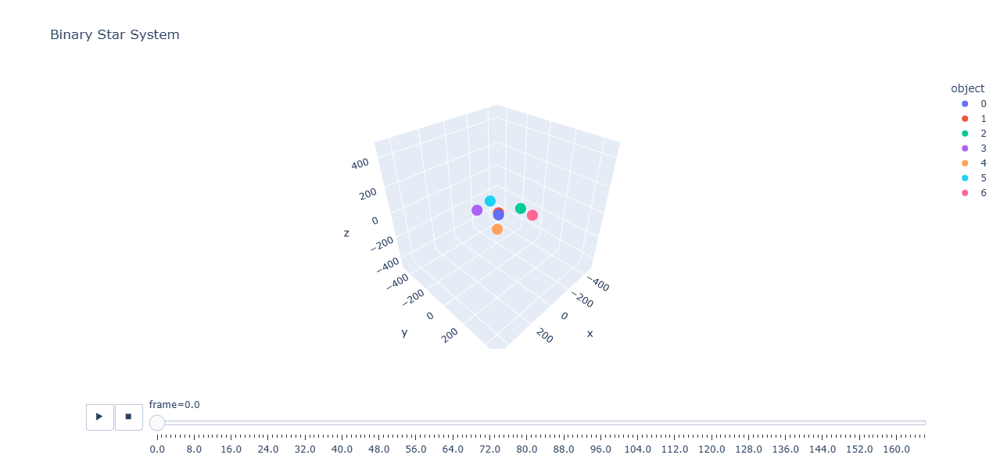

In [7]:
# Finding the center of mass
for n in range(N):
    r_cm = np.array([np.sum(objects[n,1])*objects[n,0], np.sum(objects[n,2])*objects[n,0], np.sum(objects[n,3])*objects[n,0]])/(np.sum(objects[:,0]))

# Calculating the initial momenta according to the equations derived
objects[2:N,4:7] = initial_planet_p(objects, N, r_cm, orbital_plane)

objects[0:2,4:7] = intital_star_p(objects, sm0, sm1, orbital_plane)

ini_objects = objects.copy()

for i in range(N):
    for j in range(objects[0,:].size):
        if i != j:
            objects[i,j] = objects[i,j] + (0.5 * (np.random.random()*2 - 1)*(objects[i,j]))         

while t<Time:
    
    frames, objects[:,4:7] = force_calculation(objects, N, G, soft_len, dt, frame_num)
    
    t += dt
    frame_num += 1

# Converting saved position data into a format that px.scatter_3d can use
df = pd.DataFrame(frames, columns=['x','y','z','object','frame'])

fig = anim_plot(df, R,'Binary Star System')
fig.show()

Given that the blue and red objects are the two stars, and the other points are planets, it is clear how the bodies move over time in 3D space just from calculating forces and applying eulers method to get the change in position. 

### Graph Object Animation

What if a more customizable graph is desired? Or a specific attribute isnt available in plotly express?

That is where graph objects come in. They require more work, as the figure, objects, buttons, and properties have to be applied manually. However, since you define the objects, you can make the graph do a lot more than with the express package.

We can add the graph object plotly module to the notebook by using:
>import plotly.graph_objects as go

Let's say that for the orbital simulation, it would be beneficial to see the trails of the objects as they orbit around the binary star system. To do this, the physics and data stay the same, but how it is processed has to be completely redone from scratch.

After translating the data to a tabular data structure, such as a dataframe, the objects have to be specifically designated using ids like this:

In [10]:
import plotly.graph_objects as go
object_ids = sorted(df['object'].unique())

Then the data can be tracked seperately depending on its id, and the initial set up of the plot can be made:

In [11]:
data = [] # Setting an empty list for the object data

for obj in object_ids: # For every unique objects in objects_ids
    
    # Defines the initial dataframe
    d0 = df[
        (df['object'] == obj) &
        (df['frame'] == 0)
    ]

    # Creates the object marker
    data.append(
        go.Scatter3d(
            x=d0['x'],
            y=d0['y'],
            z=d0['z'],
            mode='markers', # Setting the type of graph object to filter
            marker=dict(size=5),
            name=f'Object {obj}'
        )
    )

    # Creates the trail
    data.append(
        go.Scatter3d(
            x=[],
            y=[],
            z=[],
            mode='lines',
            line=dict(width=2),
            showlegend=False
        )
    )

Now that the objects are initialized as graph objects with both the marker and the trail, the figure can be created and the graph objects can be updated as the assigned frame number increases. 

In [12]:
fig = go.Figure(
    data=data
)

plotly_frames = []

trail_length = 300

for f in sorted(df['frame'].unique()):

    frame_data = []

    for obj in object_ids:
        
        # Setting the specific object to its data values at a certain frame
        current = df[
            (df['object'] == obj) &
            (df['frame'] == f)
        ]

        # Setting the specific objects to its current data values and all previous ones at a certain frame
        trail = df[
            (df['object'] == obj) &
            (df['frame'] >= max(0, f-trail_length)) & # Defines the oldest allowed frame data
            (df['frame'] <= f)
        ]

        # Marker update
        frame_data.append(
            go.Scatter3d(
                x=current['x'],
                y=current['y'],
                z=current['z'],
                mode='markers',
                marker=dict(size=5)
            )
        )

        # Trail update
        frame_data.append(
            go.Scatter3d(
                x=trail['x'],
                y=trail['y'],
                z=trail['z'],
                mode='lines',
                line=dict(width=2)
            )
        )

    plotly_frames.append(
        go.Frame(
            data=frame_data,
            name=str(f)
        )
    )
    
fig.frames = plotly_frames

The main animation is now made, and all that is left to do is customize the figure and add the buttons:

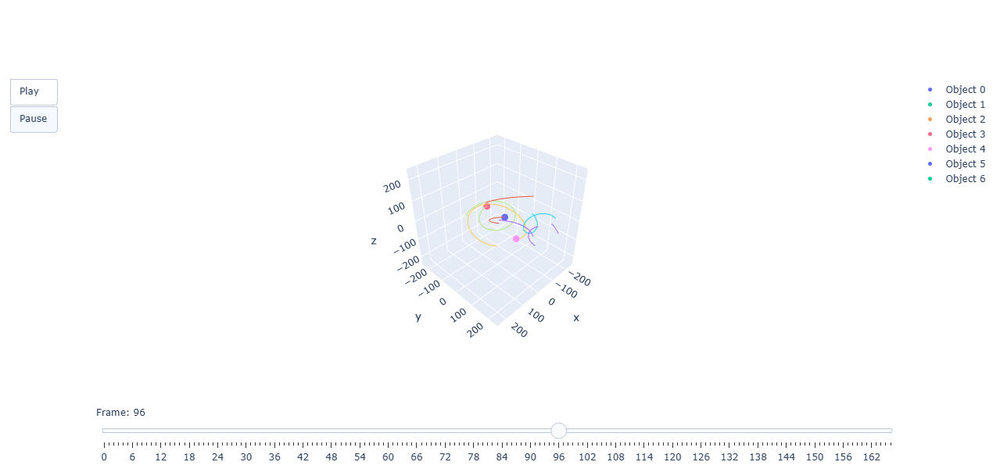

In [13]:
# Adds the slider
slider_steps = []

for f in sorted(df['frame'].unique()):

    slider_steps.append(
        dict(
            method="animate",
            args=[
                [str(f)],
                {
                    "mode": "immediate",
                    "frame": {"duration": 0, "redraw": True},
                    "transition": {"duration": 0}
                }
            ],
            label=str(int(f))
        )
    )

fig.update_layout(
    sliders=[
        dict(
            active=0,
            currentvalue={"prefix": "Frame: "},
            pad={"t": 50},
            steps=slider_steps
        )
    ]
)
    
# Adds the start and pause buttons
fig.update_layout(
    updatemenus=[
        dict(
            type="buttons",
            buttons=[
                dict(
                    label="Play",
                    method="animate",
                    args=[
                        None,
                        {
                            "frame": {"duration": 10, "redraw": True},
                            "transition": {"duration": 0},
                            "fromcurrent": True
                        }
                    ]
                ),
                dict(
                    label="Pause",
                    method="animate",
                    args=[
                        [None],
                        {
                            "frame": {"duration": 0, "redraw": False},
                            "mode": "immediate",
                            "transition": {"duration": 0}
                        }
                    ]
                )
            ]
        )
    ]
)

# Makes the graph the correct size
fig.update_layout(
    width = 600,
    height = 600,
    scene=dict(
        xaxis=dict(range=[-R, R]),
        yaxis=dict(range=[-R, R]),
        zaxis=dict(range=[-R, R]),
        aspectmode='cube'
    )
)


### 3D Orbits with Trajectories Full Example

In [14]:
# Simulation Variables

N = 7 # Number of objects
G = 1 # Gravitational Constant (set to 1 for simplicity, can be changed to real value if desired)

orbital_plane = np.array([0,0,1])

sm0 = 2500 # Mass of star 1
rsx0 = 25 ; rsy0 = 25 ; rsz0 = 20 #Initial position of star 1
sm1 = 2500 # Mass of star 2
rsx1 = -25 ; rsy1 = -25 ; rsz1 = -10 #Initial position of star 2

m0 = 1 # Mass of planet 1
rx0 = -150 ; ry0 = 50 ; rz0 = -30 #Intitial position of planet 1
m1 = 1 # Mass of planet 2
rx1 = 90 ; ry1 = -120 ; rz1 = 15 #Intitial position of planet 2
m2 = 1 # Mass of planet 3
rx2 = 110 ; ry2 = 90 ; rz2 = -10 #Intitial position of planet 3
m3 = 1 # Mass of planet 4
rx3 = -60 ; ry3 = -170 ; rz3 = 40 #Intitial position of planet 4
m4 = 1 # Mass of planet 5
rx4 = -210 ; ry4 = 130 ; rz4 = 25 #Intitial position of planet 5

R = (rx4**2 + ry4**2 + rz4**2)**(1/2) # Maximum radius for plot
M = 1

dt = 0.01 # Timestep
Time = 400 # Duration of the simulation
frame_skip = 250 # Number of timesteps between frames
soft_len = 0.1 # Softening Length to prevent singularities in force calculations when objects get very close to each other

frames = [] # Setting the empty frame list
frame_num = 0 # Intializing frame number
t = 0 # Intializing time

# Initializing array with initial conditions
objects = np.zeros([N,10])

objects[0,0] = sm0
objects[0,1:4] = np.array((rsx0, rsy0, rsz0))

objects[1,0] = sm1
objects[1,1:4] = np.array((rsx1, rsy1, rsz1))

objects[2,0] = m0
objects[2,1:4] = np.array((rx0, ry0, rz0))

objects[3,0] = m1
objects[3,1:4] = np.array((rx1, ry1, rz1))

objects[4,0] = m2
objects[4,1:4] = np.array((rx2, ry2, rz2))

objects[5,0] = m3
objects[5,1:4] = np.array((rx3, ry3, rz3))

objects[6,0] = m4
objects[6,1:4] = np.array((rx4, ry4, rz4))

objects[2:7,0] = M

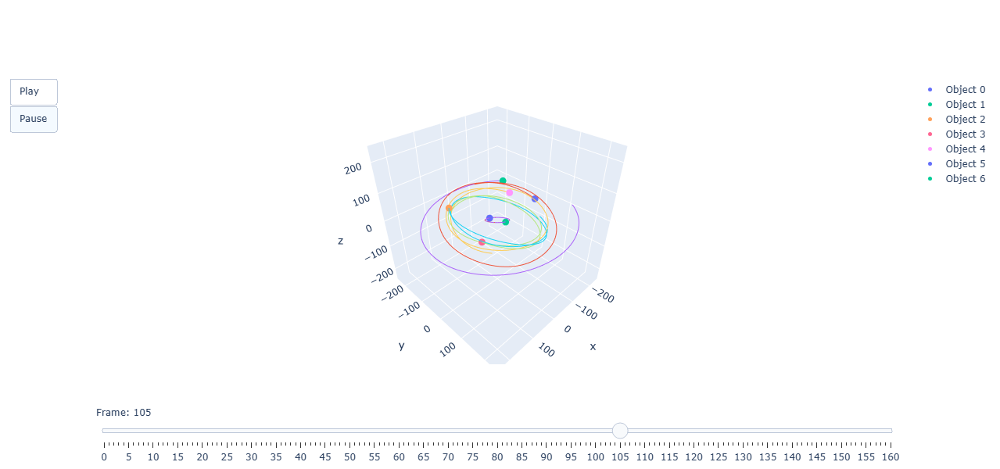

In [15]:
import plotly.graph_objects as go

# Finding the center of mass
for n in range(N):
    r_cm = np.array([np.sum(objects[n,1])*objects[n,0], np.sum(objects[n,2])*objects[n,0], np.sum(objects[n,3])*objects[n,0]])/(np.sum(objects[:,0]))

# Calculating the initial momenta according to the equations derived
objects[2:N,4:7] = initial_planet_p(objects, N, r_cm, orbital_plane)

objects[0:2,4:7] = intital_star_p(objects, sm0, sm1, orbital_plane)     

while t<Time:
    
    frames, objects[:,4:7] = force_calculation(objects, N, G, soft_len, dt, frame_num)
    
    t += dt
    frame_num += 1

# Converting saved position data into a format that px.scatter_3d can use
df = pd.DataFrame(frames, columns=['x','y','z','object','frame'])

object_ids = sorted(df['object'].unique())

data = []

for obj in object_ids:

    d0 = df[
        (df['object'] == obj) &
        (df['frame'] == 0)
    ]

    # object marker
    data.append(
        go.Scatter3d(
            x=d0['x'],
            y=d0['y'],
            z=d0['z'],
            mode='markers',
            marker=dict(size=5),
            name=f'Object {obj}'
        )
    )

    # trail
    data.append(
        go.Scatter3d(
            x=[],
            y=[],
            z=[],
            mode='lines',
            line=dict(width=2),
            showlegend=False
        )
    )

fig = go.Figure(
    data=data
)

plotly_frames = []

trail_length = 300

for f in sorted(df['frame'].unique()):

    frame_data = []

    for obj in object_ids:

        current = df[
            (df['object'] == obj) &
            (df['frame'] == f)
        ]

        trail = df[
            (df['object'] == obj) &
            (df['frame'] >= max(0, f-trail_length)) &
            (df['frame'] <= f)
        ]

        # marker
        frame_data.append(
            go.Scatter3d(
                x=current['x'],
                y=current['y'],
                z=current['z'],
                mode='markers',
                marker=dict(size=5)
            )
        )

        # trail
        frame_data.append(
            go.Scatter3d(
                x=trail['x'],
                y=trail['y'],
                z=trail['z'],
                mode='lines',
                line=dict(width=2)
            )
        )

    plotly_frames.append(
        go.Frame(
            data=frame_data,
            name=str(f)
        )
    )
    
fig.frames = plotly_frames

slider_steps = []

for f in sorted(df['frame'].unique()):

    slider_steps.append(
        dict(
            method="animate",
            args=[
                [str(f)],
                {
                    "mode": "immediate",
                    "frame": {"duration": 0, "redraw": True},
                    "transition": {"duration": 0}
                }
            ],
            label=str(int(f))
        )
    )
    
fig.update_layout(
    sliders=[
        dict(
            active=0,
            currentvalue={"prefix": "Frame: "},
            pad={"t": 50},
            steps=slider_steps
        )
    ]
)

fig.update_layout(
    updatemenus=[
        dict(
            type="buttons",
            buttons=[
                dict(
                    label="Play",
                    method="animate",
                    args=[
                        None,
                        {
                            "frame": {"duration": 10, "redraw": True},
                            "transition": {"duration": 0},
                            "fromcurrent": True
                        }
                    ]
                ),
                dict(
                    label="Pause",
                    method="animate",
                    args=[
                        [None],
                        {
                            "frame": {"duration": 0, "redraw": False},
                            "mode": "immediate",
                            "transition": {"duration": 0}
                        }
                    ]
                )
            ]
        )
    ]
)

fig.update_layout(
    width = 600,
    height = 600,
    scene=dict(
        xaxis=dict(range=[-R, R]),
        yaxis=dict(range=[-R, R]),
        zaxis=dict(range=[-R, R]),
        aspectmode='cube'
    )
)

fig.show()

The graph objects method trades accessability and ease for its customization. Depending on the data you have and how you want to represent it, you can decide whether to use express or graph objects. The best place to find information reguarding graph object information is plotly's vast documentation on their functions. It gets incredibly in depth, and many of the button-making was simply used from their examples.